In [1]:
!pip install tensorflow

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical

# Load your dataset (adjust the file path)
data_df = pd.read_csv('multisensor_posture_samples.csv')

# Separate features (Ax, Ay, Az) and labels (position classes)
dataset = data_df[['Ax', 'Ay', 'Az', 'Gx','Gy','Gz','Mx','My','Mz']]

accelerometer_data = data_df.iloc[1:, 0:3]
gyroscope_data = data_df.iloc[1:, 3:6]
magnetometer_data = data_df.iloc[1:, 6:9]

training_data = np.hstack((accelerometer_data, gyroscope_data, magnetometer_data))

X = training_data

#height = 3
#width = 3 
#X = X.values.reshape(-1, height, width)  # Reshape to have 3 channels with 3 values each

y = data_df['labels'].iloc[1:]


y = y - 1 # to transform the labels starting from '1' to '0' as frameworks like tensor flow accept labels starting from '0'

In [3]:
# Get the number of unique classes in your labels
#num_classes = len(np.unique(y))

# One-hot encode the labels with the correct number of classes
y = to_categorical(y, num_classes=5)

#y = to_categorical(y)

In [4]:
# Split data into training, validation, and test sets
train_ratio = 0.7  # Adjust the ratio as needed
val_ratio = 0.15
test_ratio = 0.15

# Split the data into training and validation sets

# First, split into train and temp sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=(1 - train_ratio), random_state=42)

# Then, split the temp set into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=test_ratio / (test_ratio + val_ratio), random_state=42)


In [5]:
import tensorflow as tf
from tensorflow import keras

# Define the neural network architecture
model_sensor = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(9,)),
    #keras.layers.Dense(128, activation='relu', input_shape=(3,3)),
    
    #keras.layers.Flatten(),  # Flatten the input
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(5, activation='softmax')  # 5 classes for 'supine' to 'unknown posture'
])

# Compile the model
model_sensor.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Display a summary of the model's architecture
model_sensor.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               1280      
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 5)                 165       
                                                                 
Total params: 11781 (46.02 KB)
Trainable params: 11781 (46.02 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [6]:
# Train the model
history_sensor = model_sensor.fit(X_train, y_train, epochs=500, batch_size=32, validation_data=(X_val, y_val))


Epoch 1/500
61/61 [==============================] - 0s 2ms/step - loss: 1.7024 - accuracy: 0.6255 - val_loss: 0.7861 - val_accuracy: 0.8072
Epoch 2/500
61/61 [==============================] - 0s 1ms/step - loss: 0.6646 - accuracy: 0.8027 - val_loss: 0.6407 - val_accuracy: 0.8337
Epoch 3/500
61/61 [==============================] - 0s 1ms/step - loss: 0.5406 - accuracy: 0.8115 - val_loss: 0.6750 - val_accuracy: 0.8337
Epoch 4/500
61/61 [==============================] - 0s 1ms/step - loss: 0.5082 - accuracy: 0.8239 - val_loss: 0.5254 - val_accuracy: 0.8602
Epoch 5/500
61/61 [==============================] - 0s 1ms/step - loss: 0.4359 - accuracy: 0.8394 - val_loss: 0.5580 - val_accuracy: 0.8410
Epoch 6/500
61/61 [==============================] - 0s 1ms/step - loss: 0.4246 - accuracy: 0.8342 - val_loss: 0.5909 - val_accuracy: 0.8602
Epoch 7/500
61/61 [==============================] - 0s 1ms/step - loss: 0.4169 - accuracy: 0.8461 - val_loss: 0.4942 - val_accuracy: 0.8675
Epoch 8/500
6

61/61 [==============================] - 0s 994us/step - loss: 0.1405 - accuracy: 0.9437 - val_loss: 0.6662 - val_accuracy: 0.8675
Epoch 59/500
61/61 [==============================] - 0s 988us/step - loss: 0.1403 - accuracy: 0.9463 - val_loss: 0.6634 - val_accuracy: 0.8530
Epoch 60/500
61/61 [==============================] - 0s 964us/step - loss: 0.1467 - accuracy: 0.9406 - val_loss: 0.6216 - val_accuracy: 0.8771
Epoch 61/500
61/61 [==============================] - 0s 977us/step - loss: 0.1586 - accuracy: 0.9380 - val_loss: 0.7423 - val_accuracy: 0.8458
Epoch 62/500
61/61 [==============================] - 0s 973us/step - loss: 0.1520 - accuracy: 0.9411 - val_loss: 0.7903 - val_accuracy: 0.8627
Epoch 63/500
61/61 [==============================] - 0s 968us/step - loss: 0.1472 - accuracy: 0.9427 - val_loss: 0.7796 - val_accuracy: 0.8434
Epoch 64/500
61/61 [==============================] - 0s 966us/step - loss: 0.1299 - accuracy: 0.9504 - val_loss: 0.7008 - val_accuracy: 0.8675
Epoch

Epoch 115/500
61/61 [==============================] - 0s 966us/step - loss: 0.0801 - accuracy: 0.9752 - val_loss: 0.9722 - val_accuracy: 0.8482
Epoch 116/500
61/61 [==============================] - 0s 951us/step - loss: 0.0694 - accuracy: 0.9747 - val_loss: 0.9359 - val_accuracy: 0.8602
Epoch 117/500
61/61 [==============================] - 0s 968us/step - loss: 0.0716 - accuracy: 0.9721 - val_loss: 1.0525 - val_accuracy: 0.8506
Epoch 118/500
61/61 [==============================] - 0s 976us/step - loss: 0.0718 - accuracy: 0.9737 - val_loss: 1.0576 - val_accuracy: 0.8651
Epoch 119/500
61/61 [==============================] - 0s 976us/step - loss: 0.0661 - accuracy: 0.9799 - val_loss: 0.9621 - val_accuracy: 0.8530
Epoch 120/500
61/61 [==============================] - 0s 969us/step - loss: 0.0656 - accuracy: 0.9768 - val_loss: 0.9658 - val_accuracy: 0.8578
Epoch 121/500
61/61 [==============================] - 0s 970us/step - loss: 0.0782 - accuracy: 0.9685 - val_loss: 1.0295 - val_ac

61/61 [==============================] - 0s 966us/step - loss: 0.0606 - accuracy: 0.9799 - val_loss: 1.0981 - val_accuracy: 0.8506
Epoch 172/500
61/61 [==============================] - 0s 973us/step - loss: 0.0533 - accuracy: 0.9809 - val_loss: 1.1656 - val_accuracy: 0.8530
Epoch 173/500
61/61 [==============================] - 0s 965us/step - loss: 0.0461 - accuracy: 0.9850 - val_loss: 1.1040 - val_accuracy: 0.8699
Epoch 174/500
61/61 [==============================] - 0s 968us/step - loss: 0.0466 - accuracy: 0.9850 - val_loss: 1.1760 - val_accuracy: 0.8578
Epoch 175/500
61/61 [==============================] - 0s 966us/step - loss: 0.0421 - accuracy: 0.9850 - val_loss: 1.1732 - val_accuracy: 0.8554
Epoch 176/500
61/61 [==============================] - 0s 977us/step - loss: 0.0467 - accuracy: 0.9830 - val_loss: 1.1811 - val_accuracy: 0.8578
Epoch 177/500
61/61 [==============================] - 0s 975us/step - loss: 0.0478 - accuracy: 0.9819 - val_loss: 1.1512 - val_accuracy: 0.8554

Epoch 228/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0321 - accuracy: 0.9912 - val_loss: 1.3824 - val_accuracy: 0.8554
Epoch 229/500
61/61 [==============================] - 0s 999us/step - loss: 0.0409 - accuracy: 0.9824 - val_loss: 1.4734 - val_accuracy: 0.8482
Epoch 230/500
61/61 [==============================] - 0s 986us/step - loss: 0.0387 - accuracy: 0.9855 - val_loss: 1.4814 - val_accuracy: 0.8410
Epoch 231/500
61/61 [==============================] - 0s 940us/step - loss: 0.0554 - accuracy: 0.9804 - val_loss: 1.5119 - val_accuracy: 0.8458
Epoch 232/500
61/61 [==============================] - 0s 972us/step - loss: 0.0640 - accuracy: 0.9809 - val_loss: 1.4451 - val_accuracy: 0.8482
Epoch 233/500
61/61 [==============================] - 0s 966us/step - loss: 0.0606 - accuracy: 0.9819 - val_loss: 1.5038 - val_accuracy: 0.8458
Epoch 234/500
61/61 [==============================] - 0s 974us/step - loss: 0.1075 - accuracy: 0.9675 - val_loss: 1.5745 - val_accu

61/61 [==============================] - 0s 974us/step - loss: 0.0494 - accuracy: 0.9840 - val_loss: 1.6225 - val_accuracy: 0.8458
Epoch 285/500
61/61 [==============================] - 0s 973us/step - loss: 0.0309 - accuracy: 0.9886 - val_loss: 1.5999 - val_accuracy: 0.8482
Epoch 286/500
61/61 [==============================] - 0s 970us/step - loss: 0.0381 - accuracy: 0.9855 - val_loss: 1.6582 - val_accuracy: 0.8554
Epoch 287/500
61/61 [==============================] - 0s 959us/step - loss: 0.0323 - accuracy: 0.9881 - val_loss: 1.6859 - val_accuracy: 0.8482
Epoch 288/500
61/61 [==============================] - 0s 962us/step - loss: 0.0256 - accuracy: 0.9912 - val_loss: 1.7038 - val_accuracy: 0.8434
Epoch 289/500
61/61 [==============================] - 0s 948us/step - loss: 0.0311 - accuracy: 0.9897 - val_loss: 1.6814 - val_accuracy: 0.8410
Epoch 290/500
61/61 [==============================] - 0s 962us/step - loss: 0.0297 - accuracy: 0.9892 - val_loss: 1.6871 - val_accuracy: 0.8410

Epoch 341/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0275 - accuracy: 0.9902 - val_loss: 1.5152 - val_accuracy: 0.8627
Epoch 342/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0296 - accuracy: 0.9886 - val_loss: 1.4933 - val_accuracy: 0.8723
Epoch 343/500
61/61 [==============================] - 0s 991us/step - loss: 0.0323 - accuracy: 0.9892 - val_loss: 1.5383 - val_accuracy: 0.8554
Epoch 344/500
61/61 [==============================] - 0s 981us/step - loss: 0.0310 - accuracy: 0.9923 - val_loss: 1.5048 - val_accuracy: 0.8675
Epoch 345/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0284 - accuracy: 0.9881 - val_loss: 1.6177 - val_accuracy: 0.8530
Epoch 346/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0346 - accuracy: 0.9897 - val_loss: 1.5158 - val_accuracy: 0.8554
Epoch 347/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0453 - accuracy: 0.9855 - val_loss: 1.5626 - val_accuracy: 0.

61/61 [==============================] - 0s 1ms/step - loss: 0.0202 - accuracy: 0.9938 - val_loss: 1.6834 - val_accuracy: 0.8410
Epoch 399/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0175 - accuracy: 0.9917 - val_loss: 1.6865 - val_accuracy: 0.8361
Epoch 400/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0197 - accuracy: 0.9928 - val_loss: 1.7263 - val_accuracy: 0.8482
Epoch 401/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0201 - accuracy: 0.9928 - val_loss: 1.6973 - val_accuracy: 0.8458
Epoch 402/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0207 - accuracy: 0.9933 - val_loss: 1.7215 - val_accuracy: 0.8458
Epoch 403/500
61/61 [==============================] - 0s 982us/step - loss: 0.0185 - accuracy: 0.9923 - val_loss: 1.7272 - val_accuracy: 0.8434
Epoch 404/500
61/61 [==============================] - 0s 983us/step - loss: 0.0183 - accuracy: 0.9933 - val_loss: 1.7433 - val_accuracy: 0.8434
Epoch 405

61/61 [==============================] - 0s 1ms/step - loss: 0.1137 - accuracy: 0.9721 - val_loss: 1.8525 - val_accuracy: 0.8241
Epoch 456/500
61/61 [==============================] - 0s 1ms/step - loss: 0.2355 - accuracy: 0.9447 - val_loss: 1.6896 - val_accuracy: 0.8386
Epoch 457/500
61/61 [==============================] - 0s 1ms/step - loss: 0.2085 - accuracy: 0.9416 - val_loss: 1.6930 - val_accuracy: 0.8361
Epoch 458/500
61/61 [==============================] - 0s 1ms/step - loss: 0.1567 - accuracy: 0.9571 - val_loss: 1.7475 - val_accuracy: 0.8410
Epoch 459/500
61/61 [==============================] - 0s 1ms/step - loss: 0.2276 - accuracy: 0.9514 - val_loss: 1.7965 - val_accuracy: 0.8120
Epoch 460/500
61/61 [==============================] - 0s 1ms/step - loss: 0.1226 - accuracy: 0.9669 - val_loss: 1.7271 - val_accuracy: 0.8313
Epoch 461/500
61/61 [==============================] - 0s 1ms/step - loss: 0.0403 - accuracy: 0.9902 - val_loss: 1.7450 - val_accuracy: 0.8361
Epoch 462/500

13/13 [==============================] - 0s 602us/step - loss: 1.4563 - accuracy: 0.8101
Sensor Model - Test Accuracy: 0.8100961446762085


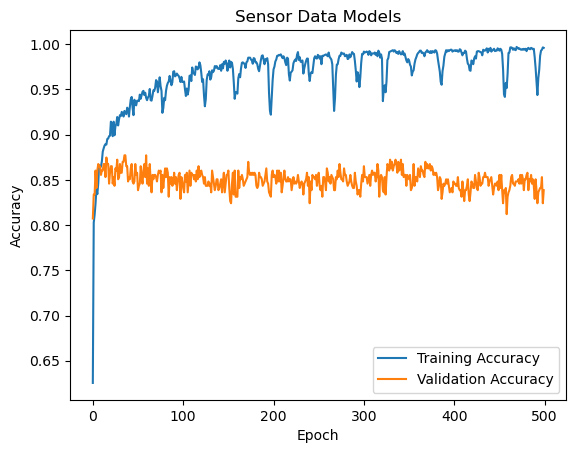

In [7]:
# Evaluate the model on the test set

score_sensor = model_sensor.evaluate(X_test, y_test)

print("Sensor Model - Test Accuracy:", score_sensor[1])

#Visualize training and validation metrics
import matplotlib.pyplot as plt

plt.plot(history_sensor.history['accuracy'], label='Training Accuracy')
plt.plot(history_sensor.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Sensor Data Models')
plt.legend()
plt.show()

In [8]:
# Save the entire model in TensorFlow's SavedModel format
#model_sensor.save("sensor_model")
model_sensor.save("sensor_model.h5")

/Users/manishkumar/anaconda3/lib/python3.11/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [9]:
import tensorflow as tf
import os

from tensorflow.lite.python import tflite_convert

# Load the saved model
model = tf.keras.models.load_model("sensor_model.h5")

# Convert the model to TFLite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

tflite_model_path = "posture_classifier.tflite"

# Save the TFLite model to a file
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)

print(f"Model saved as {tflite_model_path}")

# Specify the folder where you want to save the generated C/C++ code
# output_folder = os.path.expanduser("~/Desktop/P4/GeneratedCode") 
# tflite_convert.from_saved_model(tflite_model_path, output_folder)


INFO:tensorflow:Assets written to: /var/folders/ts/r07mqb3j6hzbljxlx3g8mmv80000gn/T/tmpj_tvmjro/assets


INFO:tensorflow:Assets written to: /var/folders/ts/r07mqb3j6hzbljxlx3g8mmv80000gn/T/tmpj_tvmjro/assets
2023-10-17 10:59:00.842014: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:378] Ignored output_format.
2023-10-17 10:59:00.842030: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:381] Ignored drop_control_dependency.
2023-10-17 10:59:00.842260: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/ts/r07mqb3j6hzbljxlx3g8mmv80000gn/T/tmpj_tvmjro
2023-10-17 10:59:00.842958: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2023-10-17 10:59:00.842963: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: /var/folders/ts/r07mqb3j6hzbljxlx3g8mmv80000gn/T/tmpj_tvmjro
2023-10-17 10:59:00.844311: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:382] MLIR V1 optimization pass is not enabled
2023-10-17 10:59:00.844929: I tensorflow/cc/saved_model/load

Model saved as /Users/manishkumar/Desktop/Mini_Project_4/sensor_model.tflite


In [10]:
# Load the TensorFlow Lite model
interpreter = tf.lite.Interpreter(model_path='posture_classifier.tflite')

interpreter.allocate_tensors()

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


87/87 [==============================] - 0s 453us/step


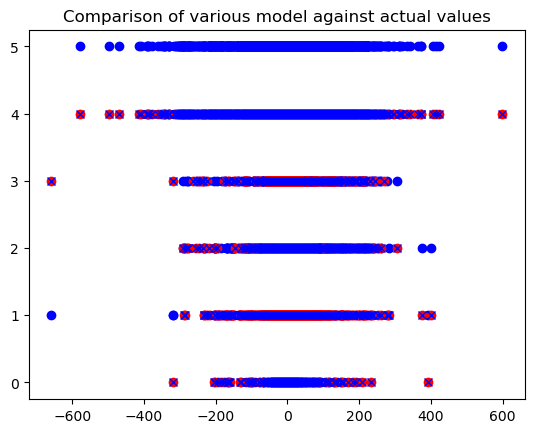

In [11]:
# Assuming your dataset is stored in a variable 'data', where data[1:] represents the data excluding the first row with labels.
#data = ...  # Replace with your actual dataset

# Skip the first row containing column names and labels
#data = data_df.iloc[1:]

# Extract the features (X) and labels (y) from the dataset
#X_test = data_df.iloc[:, :-1]  # Assuming the last column is the label
y_test = data_df.iloc[1:, -1]

# Convert the X_test and y_test DataFrames to NumPy arrays if needed
X_test = training_data
y_test = y_test.values

# Prepare your input data (replace this with your actual data)
input_tensor_index = interpreter.get_input_details()[0]['index']
output_tensor_index = interpreter.get_output_details()[0]['index']

model_prediction=[]

predictions=model.predict(X_test)
y_pred_labels = np.argmax(predictions, axis=1)

for val in X_test:
  input_data = tf.convert_to_tensor([val], dtype=np.float32)
  input_details = interpreter.get_input_details()
    
  input_tensor_index = input_details[0]['index']
 
  interpreter.set_tensor(input_tensor_index, input_data)
 
  interpreter.invoke()
  model_prediction.append(interpreter.get_tensor(output_tensor_index)[0])
    
  
result1 = np.argmax(model_prediction, axis=1)

plt.clf()
plt.title('Comparison of various model against actual values')
plt.plot(X_test, y_test, 'bo', label='Actual')
plt.plot(X_test, y_pred_labels, 'ro', label='Original Predictions')

plt.plot(X_test, result1, 'bx', label='Lite Prediction')

In [12]:
!apt-get -qq install xxd
!xxd -i posture_classifier.tflite > sensor_model.cc
!cat sensor_model.cc 

zsh:1: command not found: apt-get
zsh:1: command not found: cat sensor_model.cc


In [13]:
"""import sys

# Load the binary model file
with open('posture_classifier.tflite', 'rb') as model_file:
    model_data = model_file.read()

# Create a C array file
with open('model_sample.h', 'w') as array_file:
    array_file.write('#ifndef POSTURE_MODEL_H\n')
    array_file.write('#define POSTURE_MODEL_H\n\n')
    array_file.write('const unsigned char model_data[] = {\n')
    for i in range(0, len(model_data)):
        if i % 12 == 0:
            array_file.write('  ')
        array_file.write(f'0x{model_data[i]:02X}')
        if i < len(model_data) - 1:
            array_file.write(', ')
        if (i + 1) % 12 == 0:
            array_file.write('\n')
    array_file.write('\n};\n')
    array_file.write('#endif  // POSTURE_MODEL_H\n')"""